<a href="https://colab.research.google.com/github/ilhamajikusuma/25523172_Regresi_FSD/blob/main/B%20%E2%80%93%20Logistic%20Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Bagian B – Logistic Regression**

Nama: ILHAM AJI KUSUMA

NIM: 25523172

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score)

sns.set_theme(style='whitegrid')

# **B1 – Deskripsi Dataset**

In [5]:
df_raw = sns.load_dataset('titanic')
print(df_raw.shape)
df_raw.info()
df_raw.head()

(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [6]:
df_raw.to_csv('titanic.csv', index=False)
from google.colab import files
files.download('titanic.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## B1 – Deskripsi Dataset

**Sumber:** Titanic, dimuat dari library seaborn (`sns.load_dataset('titanic')`). Dataset ini berisi data penumpang kapal RMS Titanic yang tenggelam pada tahun 1912.

**Ukuran:** 891 baris dan 15 kolom. Setiap baris mewakili satu penumpang.

**Arti kolom yang digunakan:**
- `survived`: status keselamatan (target)
- `pclass`: kelas tiket (1 = kelas satu, 2 = kelas dua, 3 = kelas tiga)
- `sex`: jenis kelamin (male/female)
- `age`: usia (tahun)
- `sibsp`: jumlah saudara kandung/pasangan yang ikut di kapal
- `parch`: jumlah orang tua/anak yang ikut di kapal
- `fare`: harga tiket
- `embarked`: pelabuhan keberangkatan (C = Cherbourg, Q = Queenstown, S = Southampton)

Kolom lain (`class`, `who`, `adult_male`, `deck`, `embark_town`, `alive`, `alone`) tidak dipakai; alasannya dijelaskan di B3.

**Variabel target:** `survived`, dengan dua kelas:
- **0** = tidak selamat
- **1** = selamat (kelas positif)

# **B2 – Eksplorasi dan Visualisasi**

In [ ]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


survived
0    549
1    342
Name: count, dtype: int64
survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


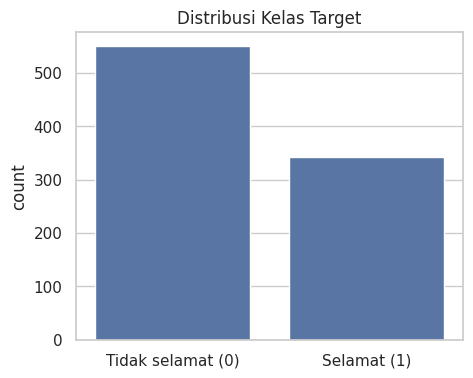

In [ ]:
kelas = df_raw['survived'].value_counts().sort_index()
print(kelas)
print(df_raw['survived'].value_counts(normalize=True).sort_index())

plt.figure(figsize=(5, 4))
sns.countplot(x='survived', data=df_raw)
plt.xticks([0, 1], ['Tidak selamat (0)', 'Selamat (1)'])
plt.title('Distribusi Kelas Target')
plt.xlabel('')
plt.show()

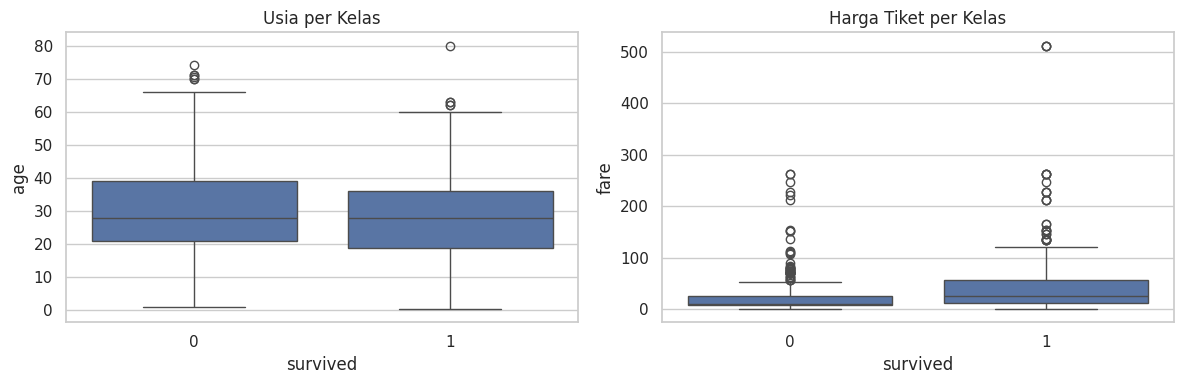

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x='survived', y='age', data=df_raw, ax=axes[0])
axes[0].set_title('Usia per Kelas')
sns.boxplot(x='survived', y='fare', data=df_raw, ax=axes[1])
axes[1].set_title('Harga Tiket per Kelas')
plt.tight_layout()
plt.show()

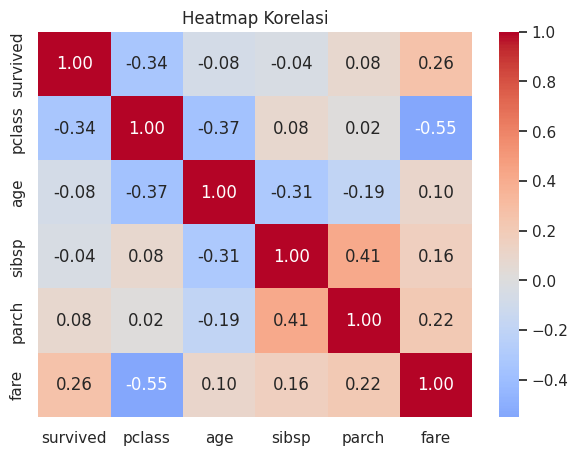

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_raw[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi')
plt.show()

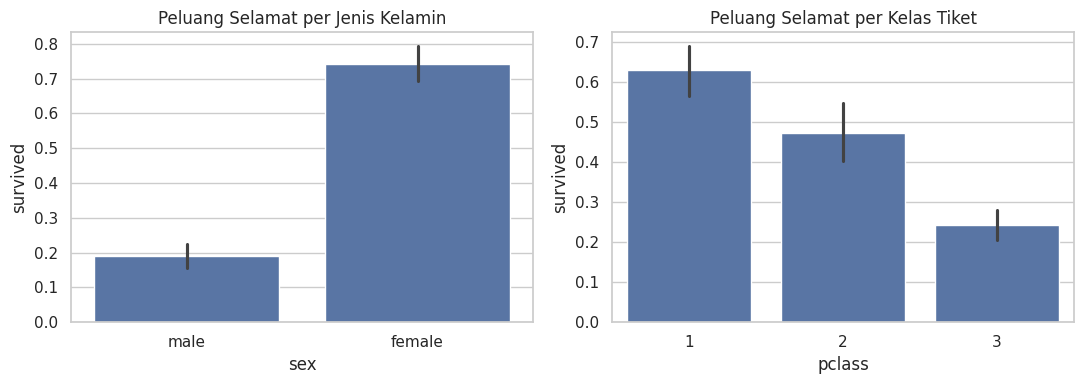

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x='sex', y='survived', data=df_raw, ax=axes[0])
axes[0].set_title('Peluang Selamat per Jenis Kelamin')
sns.barplot(x='pclass', y='survived', data=df_raw, ax=axes[1])
axes[1].set_title('Peluang Selamat per Kelas Tiket')
plt.tight_layout()
plt.show()

## B2 – Eksplorasi dan Visualisasi Data

**Statistik deskriptif.** Tabel `describe()` menunjukkan `age` hanya terisi sekitar 714 dari 891 baris, artinya ada missing values. `fare` memiliki rentang sangat lebar (dari 0 hingga lebih dari 500) dengan rata-rata jauh di atas median, menandakan distribusi condong ke kanan dan ada outlier.

**Distribusi kelas target.** Kelas tidak selamat (0) berjumlah sekitar 549 penumpang (±62%), sedangkan selamat (1) sekitar 342 penumpang (±38%). Kelas tidak seimbang secara ringan: kelas minoritas (selamat) masih cukup besar, tetapi akurasi saja bisa menyesatkan karena menebak "tidak selamat" untuk semua penumpang sudah menghasilkan akurasi sekitar 62%.

**Box plot fitur per kelas.** Sebaran usia kedua kelas sangat mirip dengan median yang berdekatan, sehingga `age` kemungkinan bukan pembeda yang kuat. Sebaliknya, penumpang yang selamat cenderung membayar tiket lebih mahal (median `fare` lebih tinggi), dan kedua kelas memiliki banyak outlier pada `fare`.

**Heatmap korelasi.** Korelasi terkuat dengan `survived` dimiliki `pclass` (negatif, sekitar -0,34: semakin tinggi nomor kelas, semakin kecil peluang selamat) dan `fare` (positif, sekitar 0,26). `age`, `sibsp`, dan `parch` berkorelasi sangat lemah dengan target. `pclass` dan `fare` berkorelasi negatif cukup kuat, wajar karena kelas yang lebih tinggi membayar lebih mahal.

**Peluang selamat per kelompok.** Perempuan memiliki peluang selamat jauh lebih tinggi dibanding laki-laki (sekitar 74% berbanding 19%), dan penumpang kelas satu memiliki peluang selamat tertinggi, turun di kelas dua dan paling rendah di kelas tiga. Ini menunjukkan jenis kelamin dan kelas tiket adalah calon prediktor yang kuat.

# **B3 – Preprocessing**

In [ ]:
df = df_raw[['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']].copy()
print(df.shape)
print('Missing values per kolom:')
print(df.isnull().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())

(891, 8)
Missing values per kolom:
survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64
Jumlah baris duplikat: 111


In [ ]:
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
print('Sisa missing values:', df.isnull().sum().sum())

Sisa missing values: 0


In [ ]:
Q1 = df[['age', 'fare']].quantile(0.25)
Q3 = df[['age', 'fare']].quantile(0.75)
IQR = Q3 - Q1
print('Jumlah outlier (aturan IQR):')
print(((df[['age', 'fare']] < Q1 - 1.5 * IQR) | (df[['age', 'fare']] > Q3 + 1.5 * IQR)).sum())

batas_fare = df['fare'].quantile(0.99)
df['fare'] = df['fare'].clip(upper=batas_fare)
print('Batas persentil 99 fare:', round(batas_fare, 2))

Jumlah outlier (aturan IQR):
age      66
fare    116
dtype: int64
Batas persentil 99 fare: 249.01


In [ ]:
df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)
df.head()

,survived,pclass,age,sibsp,parch,fare,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


In [ ]:
print(df['survived'].value_counts())
print(df['survived'].value_counts(normalize=True))

survived
0    549
1    342
Name: count, dtype: int64
survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


## B3 – Preprocessing

**Pemilihan kolom.** Kolom `class`, `who`, `adult_male`, `embark_town`, dan `alone` dibuang karena hanya turunan atau duplikat kolom lain (`pclass`, `sex`, `age`, `embarked`, `sibsp`, `parch`). Kolom `alive` dibuang karena isinya identik dengan target (yes/no); jika dipakai sebagai fitur akan terjadi *data leakage* karena model "mengintip" jawaban. Kolom `deck` dibuang karena sekitar 77% nilainya kosong sehingga imputasi tidak dapat dipercaya.

**Missing values.** `age` memiliki sekitar 177 nilai kosong dan diisi dengan **median**, bukan rata-rata, karena median lebih tahan terhadap outlier. `embarked` hanya kehilangan 2 nilai sehingga diisi dengan **modus** (pelabuhan paling sering). Menghapus baris tidak dipilih karena akan membuang hampir 20% data.

**Data duplikat.** Dicek dengan `duplicated()`. Baris duplikat **tidak dihapus** karena dataset tidak memiliki kolom ID penumpang, sehingga baris dengan nilai identik bisa jadi penumpang berbeda (misalnya anggota keluarga yang membeli tiket yang sama). Menghapusnya berisiko membuang data yang sah.

**Outlier.** Outlier dideteksi dengan aturan IQR. `fare` memiliki banyak outlier karena harga tiket kelas satu jauh lebih mahal. Nilai ini tidak dihapus karena merupakan data yang valid, tetapi dibatasi (*clipping*) pada persentil ke-99 agar beberapa tiket yang sangat mahal tidak terlalu mempengaruhi koefisien. `age` memiliki sedikit outlier (penumpang lanjut usia) yang realistis sehingga dibiarkan.

**Encoding.** `sex` dan `embarked` bersifat kategorikal sehingga diubah menjadi variabel dummy dengan `get_dummies(drop_first=True)`. Opsi `drop_first` menghindari multikolinearitas sempurna (*dummy variable trap*). Hasilnya kolom `sex_male`, `embarked_Q`, dan `embarked_S`.

**Scaling.** Model utama dilatih pada data asli agar koefisien mudah diinterpretasikan. Scaling (StandardScaler) hanya dipakai di B6 untuk membandingkan besar pengaruh antarfitur, dan scaler di-*fit* hanya pada data latih agar tidak terjadi kebocoran data.

**Ketidakseimbangan kelas.** Proporsi kelas sekitar 62% : 38%, ketidakseimbangan ringan. Dampaknya, model cenderung condong memprediksi kelas mayoritas (tidak selamat) sehingga recall untuk kelas selamat bisa rendah. Penanganannya menggunakan `class_weight='balanced'` pada model, yang memberi bobot lebih besar pada kelas minoritas. Resampling tidak dipakai agar data asli tetap utuh dan karena ketidakseimbangannya tidak ekstrem.

# **B4 – Pemilihan Fitur**

In [ ]:
X_semua = df.drop(columns='survived')
y_semua = df['survived']

korelasi = df.corr()['survived'].drop('survived').sort_values(ascending=False)
print(korelasi)

fare          0.273008
parch         0.081629
embarked_Q    0.003650
sibsp        -0.035322
age          -0.064910
embarked_S   -0.149683
pclass       -0.338481
sex_male     -0.543351
Name: survived, dtype: float64


In [ ]:
selector = SelectKBest(score_func=f_classif, k=6)
selector.fit(X_semua, y_semua)

skor = pd.DataFrame({
    'fitur': X_semua.columns,
    'F_score': selector.scores_,
    'p_value': selector.pvalues_
}).sort_values('F_score', ascending=False)
print(skor)

fitur_terpilih = list(X_semua.columns[selector.get_support()])
fitur_dibuang = [f for f in X_semua.columns if f not in fitur_terpilih]
print('\nFitur dipertahankan:', fitur_terpilih)
print('Fitur dibuang      :', fitur_dibuang)

        fitur     F_score       p_value
5    sex_male  372.405724  1.406066e-69
0      pclass  115.031272  2.537047e-25
4        fare   71.596560  1.078159e-16
7  embarked_S   20.374460  7.223241e-06
3       parch    5.963464  1.479925e-02
1         age    3.761528  5.276069e-02
2       sibsp    1.110572  2.922439e-01
6  embarked_Q    0.011846  9.133532e-01

Fitur dipertahankan: ['pclass', 'age', 'parch', 'fare', 'sex_male', 'embarked_S']
Fitur dibuang      : ['sibsp', 'embarked_Q']


## B4 – Pemilihan Fitur

Pemilihan fitur menggunakan dua pendekatan: korelasi tiap fitur dengan target, dan `SelectKBest` dengan uji ANOVA F (`f_classif`) untuk memeringkat kekuatan hubungan tiap fitur dengan kelas target. Dipilih **k = 6** fitur dengan skor F tertinggi dari 8 kandidat.

**Fitur dipertahankan (6):** `pclass`, `age`, `parch`, `fare`, `sex_male`, dan `embarked_S`. Keenamnya memiliki skor F tertinggi, artinya perbedaan nilainya antara penumpang selamat dan tidak selamat paling jelas dibanding fitur lain.

**Fitur dibuang (2):** `sibsp` dan `embarked_Q`. Keduanya memiliki skor F terendah (p-value terbesar) sehingga kemampuannya memisahkan kedua kelas paling lemah dan dibuang untuk menyederhanakan model. Informasi `sibsp` (jumlah saudara/pasangan) juga sebagian sudah terwakili oleh `parch` (jumlah orang tua/anak) yang sama-sama menggambarkan ukuran keluarga.

# **B5 – Pembagian Data**

In [ ]:
X = df[fitur_terpilih]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Data latih:', X_train.shape)
print('Data uji  :', X_test.shape)
print('\nProporsi kelas data latih:')
print(y_train.value_counts(normalize=True))
print('\nProporsi kelas data uji:')
print(y_test.value_counts(normalize=True))

Data latih: (712, 6)
Data uji  : (179, 6)

Proporsi kelas data latih:
survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

Proporsi kelas data uji:
survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


## B5 – Pembagian Data

Data dibagi 80% data latih dan 20% data uji dengan `train_test_split`. Parameter `random_state=42` menjamin pembagian yang sama setiap kali notebook dijalankan. Parameter `stratify=y` memastikan proporsi kelas selamat dan tidak selamat pada data latih dan data uji sama dengan data asli (sekitar 62% : 38%), seperti terlihat pada output di atas. Tanpa `stratify`, data uji yang kecil bisa saja mendapat proporsi kelas yang timpang sehingga evaluasi tidak adil.

# **B6 – Pemodelan**

In [ ]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train, y_train)

koef = pd.DataFrame({
    'fitur': fitur_terpilih,
    'koefisien': model.coef_[0],
    'odds_ratio': np.exp(model.coef_[0])
}).sort_values('koefisien', ascending=False)

print('Intercept:', model.intercept_[0])
koef

Intercept: 5.3150249575177195


,fitur,koefisien,odds_ratio
3,fare,0.001210,1.001211
1,age,-0.035529,0.965095
2,parch,-0.152261,0.858764
5,embarked_S,-0.502724,0.604881
0,pclass,-1.061105,0.346073
4,sex_male,-2.485887,0.083252


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
model_s = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train_s, y_train)

koef_std = pd.DataFrame({
    'fitur': fitur_terpilih,
    'koefisien_terstandarisasi': model_s.coef_[0]
})
koef_std['pengaruh_absolut'] = koef_std['koefisien_terstandarisasi'].abs()
koef_std.sort_values('pengaruh_absolut', ascending=False)

,fitur,koefisien_terstandarisasi,pengaruh_absolut
4,sex_male,-1.231094,1.231094
0,pclass,-0.899058,0.899058
1,age,-0.463957,0.463957
5,embarked_S,-0.231247,0.231247
2,parch,-0.135749,0.135749
3,fare,0.042060,0.042060


## B6 – Pemodelan

Model `LogisticRegression` dilatih pada data latih dengan `class_weight='balanced'` untuk menangani ketidakseimbangan kelas.

Logistic Regression memodelkan **log-odds** peluang kelas positif (selamat):

log( p / (1 - p) ) = intercept + b1·x1 + b2·x2 + ...

**Cara membaca koefisien:**
- Koefisien **positif** berarti kenaikan fitur menaikkan peluang selamat; koefisien **negatif** menurunkannya (dengan fitur lain tetap).
- **Odds ratio** = exp(koefisien). Nilai di atas 1 berarti peluang selamat naik, di bawah 1 berarti turun. Contoh: odds ratio 0,5 berarti odds selamat menjadi separuhnya setiap kenaikan satu satuan fitur.

**Interpretasi per fitur:**
- `sex_male`: koefisien negatif paling besar (-2,486; odds ratio 0,083). Odds selamat penumpang laki-laki hanya sekitar 8% dari perempuan, atau sekitar 12 kali lebih rendah, dengan fitur lain tetap.
- `pclass`: koefisien negatif (-1,061; odds ratio 0,346). Setiap turun satu kelas (misalnya dari kelas 1 ke 2), odds selamat turun sekitar 65%.
- `age`: koefisien negatif kecil (-0,036; odds ratio 0,965). Setiap tambahan satu tahun usia menurunkan odds selamat sekitar 3,5% (sekitar 30% untuk selisih 10 tahun).
- `embarked_S`: koefisien negatif (-0,503; odds ratio 0,605). Penumpang yang naik dari Southampton memiliki odds selamat sekitar 40% lebih rendah dibanding penumpang yang naik dari pelabuhan lain (Cherbourg atau Queenstown, karena `embarked_Q` tidak masuk model sehingga kelompok pembandingnya gabungan keduanya).
- `parch`: koefisien negatif kecil (-0,152; odds ratio 0,859). Setiap tambahan satu orang tua/anak yang ikut menurunkan odds selamat sekitar 14%.
- `fare`: koefisien hampir nol (0,0012; odds ratio 1,001). Setelah `pclass` ikut diperhitungkan, harga tiket nyaris tidak menambah informasi, karena `fare` dan `pclass` berkorelasi kuat (kelas yang lebih tinggi membayar lebih mahal) sehingga pengaruhnya sudah ditangkap `pclass`.
- **Intercept:** log-odds selamat saat semua fitur bernilai nol; tidak memiliki makna praktis karena kombinasi nol tidak realistis (misalnya `pclass` = 0).

Karena satuan fitur berbeda, koefisien pada tabel pertama tidak bisa dibandingkan langsung. Tabel kedua memakai fitur terstandarisasi hanya untuk membandingkan besar pengaruh antarfitur. Berdasarkan koefisien terstandarisasi, urutan pengaruh dari terbesar adalah `sex_male`, `pclass`, `age`, `embarked_S`, `parch`, dan `fare`.

# **B7 – Evaluasi**

In [ ]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

def hitung_metrik(y_asli, y_pred):
    return {
        'Accuracy': accuracy_score(y_asli, y_pred),
        'Precision': precision_score(y_asli, y_pred),
        'Recall': recall_score(y_asli, y_pred),
        'F1-score': f1_score(y_asli, y_pred)
    }

hasil = pd.DataFrame({
    'Data Latih': hitung_metrik(y_train, y_pred_train),
    'Data Uji': hitung_metrik(y_test, y_pred_test)
}).T
hasil

,Accuracy,Precision,Recall,F1-score
Data Latih,0.790730,0.703947,0.783883,0.741768
Data Uji,0.776536,0.683544,0.782609,0.729730


In [ ]:
print(classification_report(y_test, y_pred_test, target_names=['Tidak selamat (0)', 'Selamat (1)']))

                   precision    recall  f1-score   support

Tidak selamat (0)       0.85      0.77      0.81       110
      Selamat (1)       0.68      0.78      0.73        69

         accuracy                           0.78       179
        macro avg       0.77      0.78      0.77       179
     weighted avg       0.79      0.78      0.78       179



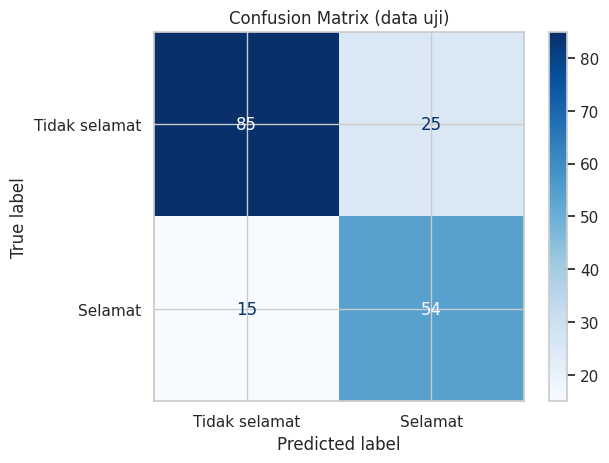

In [ ]:
cm = confusion_matrix(y_test, y_pred_test)
disp = ConfusionMatrixDisplay(cm, display_labels=['Tidak selamat', 'Selamat'])
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix (data uji)')
plt.show()

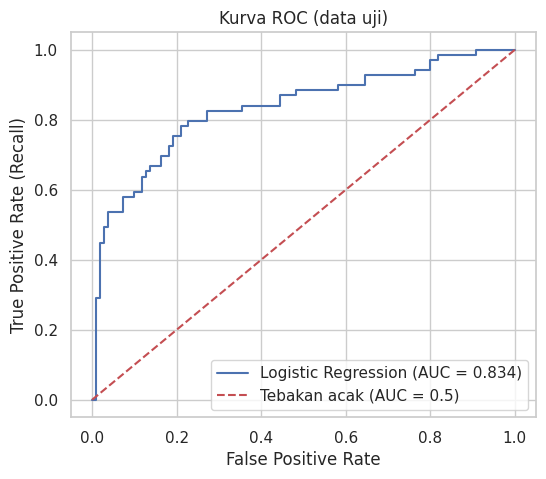

In [ ]:
proba_test = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_test)
auc = roc_auc_score(y_test, proba_test)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'r--', label='Tebakan acak (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Kurva ROC (data uji)')
plt.legend()
plt.show()

## B7 – Evaluasi

Model dievaluasi pada data latih dan data uji dengan metrik berikut (kelas positif = selamat):

- **Accuracy**: proporsi prediksi yang benar dari seluruh data.
- **Precision**: dari penumpang yang diprediksi selamat, berapa yang benar-benar selamat.
- **Recall**: dari penumpang yang benar-benar selamat, berapa yang berhasil terdeteksi model.
- **F1-score**: rata-rata harmonik precision dan recall.
- **Confusion matrix**: rincian prediksi benar dan salah per kelas (TN, FP, FN, TP).
- **Kurva ROC dan AUC**: kemampuan model membedakan kedua kelas di berbagai ambang batas; AUC 0,5 setara tebakan acak dan 1,0 sempurna.

Tabel metrik, confusion matrix, dan kurva ROC ada di sel di atas. Pembahasan dibuat di B8.

# **B8 – Analisis Performa**

In [ ]:
tn, fp, fn, tp = cm.ravel()
print(f"Accuracy latih / uji : {hasil.loc['Data Latih','Accuracy']:.3f} / {hasil.loc['Data Uji','Accuracy']:.3f}")
print(f"Precision latih / uji: {hasil.loc['Data Latih','Precision']:.3f} / {hasil.loc['Data Uji','Precision']:.3f}")
print(f"Recall latih / uji   : {hasil.loc['Data Latih','Recall']:.3f} / {hasil.loc['Data Uji','Recall']:.3f}")
print(f"F1 latih / uji       : {hasil.loc['Data Latih','F1-score']:.3f} / {hasil.loc['Data Uji','F1-score']:.3f}")
print(f"AUC uji              : {auc:.3f}")
print(f"Confusion matrix uji : TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print()
print('Fitur dipertahankan:', fitur_terpilih)
print(koef.to_string(index=False))
print()
print(koef_std.sort_values('pengaruh_absolut', ascending=False)[['fitur','koefisien_terstandarisasi']].to_string(index=False))

Accuracy latih / uji : 0.791 / 0.777
Precision latih / uji: 0.704 / 0.684
Recall latih / uji   : 0.784 / 0.783
F1 latih / uji       : 0.742 / 0.730
AUC uji              : 0.834
Confusion matrix uji : TN=85, FP=25, FN=15, TP=54

Fitur dipertahankan: ['pclass', 'age', 'parch', 'fare', 'sex_male', 'embarked_S']
     fitur  koefisien  odds_ratio
      fare   0.001210    1.001211
       age  -0.035529    0.965095
     parch  -0.152261    0.858764
embarked_S  -0.502724    0.604881
    pclass  -1.061105    0.346073
  sex_male  -2.485887    0.083252

     fitur  koefisien_terstandarisasi
  sex_male                  -1.231094
    pclass                  -0.899058
       age                  -0.463957
embarked_S                  -0.231247
     parch                  -0.135749
      fare                   0.042060


## B8 – Analisis Performa

**Hasil keseluruhan.** Pada data uji, model memperoleh accuracy 0,777, precision 0,684, recall 0,783, F1-score 0,730, dan AUC 0,834. Accuracy 77,7% lebih baik daripada baseline menebak kelas mayoritas (tidak selamat) untuk semua penumpang, yang hanya menghasilkan sekitar 61,5% pada data uji. AUC 0,834 menunjukkan model cukup baik dalam membedakan penumpang selamat dan tidak selamat di berbagai ambang batas (jauh di atas 0,5 untuk tebakan acak).

**Overfitting atau underfitting.** Metrik data latih dan uji hampir sama: accuracy 0,791 vs 0,777, precision 0,704 vs 0,684, recall 0,784 vs 0,783, dan F1 0,742 vs 0,730. Selisih yang kecil (sekitar 1-2 poin persentase) menunjukkan model **tidak overfitting** dan menggeneralisasi dengan baik. Performa yang sedang di kedua data menandakan model sederhana ini belum menangkap seluruh pola, misalnya interaksi antarfitur seperti jenis kelamin dan kelas tiket.

**Metrik yang paling relevan.** Accuracy kurang tepat dijadikan acuan utama karena kelas tidak seimbang (sekitar 62% : 38%); model yang selalu menebak "tidak selamat" sudah mendapat accuracy sekitar 62% tanpa mengenali satu pun penumpang yang selamat. Karena itu **recall kelas selamat** dan **F1-score** lebih relevan: recall menunjukkan berapa banyak penumpang yang benar-benar selamat berhasil dikenali (54 dari 69, atau 78,3%), sedangkan F1 menyeimbangkan recall dengan precision. Jika tujuan analisisnya adalah tidak melewatkan penumpang yang berpeluang selamat, recall menjadi prioritas, dengan konsekuensi precision yang lebih rendah. AUC melengkapi karena tidak bergantung pada satu ambang batas.

**Jenis kesalahan.** Dari 179 penumpang pada data uji, confusion matrix menunjukkan TN = 85, FP = 25, FN = 15, dan TP = 54. Kesalahan paling sering adalah **False Positive** (25 kasus): penumpang yang diprediksi selamat padahal tidak selamat. Sebaliknya, False Negative hanya 15 kasus: penumpang yang selamat tetapi diprediksi tidak selamat. Pola ini wajar karena `class_weight='balanced'` memberi bobot lebih besar pada kelas selamat, sehingga model lebih "berani" memprediksi selamat. Hasilnya recall tinggi (0,783) dengan precision yang lebih rendah (0,684). Dari 110 penumpang yang tidak selamat, 25 salah diprediksi (sekitar 23%); dari 69 yang selamat, 15 terlewat (sekitar 22%).

**Fitur paling berpengaruh.** Berdasarkan koefisien terstandarisasi, `sex_male` (-1,231) dan `pclass` (-0,899) adalah penentu terbesar, diikuti `age` (-0,464), `embarked_S` (-0,231), `parch` (-0,136), dan `fare` (0,042). Penumpang perempuan, penumpang kelas yang lebih tinggi, dan penumpang yang lebih muda memiliki peluang selamat lebih besar, sesuai catatan sejarah bahwa perempuan dan anak-anak serta penumpang kelas atas diprioritaskan menaiki sekoci.

**Keterbatasan model.**
1. Model mengasumsikan hubungan linear pada log-odds dan tidak menangkap interaksi antarfitur (misalnya laki-laki kelas 1 dan perempuan kelas 3 berperilaku berbeda dari efek gabungan masing-masing fitur).
2. Sekitar 20% nilai `age` kosong dan diisi dengan median, sehingga informasi usia kurang akurat dan pengaruh `age` bisa terdilusi.
3. Data uji hanya 179 penumpang, sehingga metrik cukup sensitif: perubahan beberapa penumpang saja dapat menggeser accuracy sekitar setengah poin persentase.
4. Koefisien menunjukkan asosiasi, bukan sebab-akibat. `fare` dan `pclass` berkorelasi kuat sehingga koefisien `fare` hampir nol.
5. Kolom informatif lain seperti gelar pada nama dan nomor kabin tidak dipakai, dan data bersifat historis (kapal 1912), sehingga tidak dapat digeneralisasi ke kejadian lain.
6. Perbaikan yang mungkin: menambah fitur turunan (gelar penumpang, ukuran keluarga), menambahkan interaksi antarfitur, atau mencoba model nonlinear seperti Random Forest.